NAME: Vedangi Eknath Patil

PRN: 202401040058

DIV: A

BATCH: A1

ROLL NO: 19

# Assignment No. 2: Feature Engineering
## Crop Yield Analysis Using Agricultural and Weather Data

**Aim:** To collect crop-yield data programmatically and apply data inspection, preprocessing, missing-value imputation, visualization, categorical encoding, feature engineering, and feature scaling using Python.

**Dataset:** A public Indian crop-yield CSV is downloaded from a public GitHub repository using the `requests` library. The expected dataset contains crop, year, season, state, area, production, annual rainfall, fertilizer, pesticide, and yield. The notebook checks the actual column names after loading; if the source is unavailable, it provides an upload fallback.

## 1. Import Required Libraries

In [ ]:
import io
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")


## 2. Collect the Dataset Programmatically

In [ ]:
DATA_URL = "https://raw.githubusercontent.com/Arihant-Bhandari/CROP_YIELD/main/crop_yield.csv"

try:
    response = requests.get(DATA_URL, timeout=30)
    response.raise_for_status()
    df = pd.read_csv(io.BytesIO(response.content))
    print("Dataset downloaded successfully using the Requests library.")
except Exception as e:
    print("Automatic download failed:", e)
    print("Upload the crop-yield CSV file below if the source URL is unavailable.")
    try:
        from google.colab import files
        uploaded = files.upload()
        if not uploaded:
            raise RuntimeError("No file was uploaded.")
        filename = next(iter(uploaded))
        df = pd.read_csv(io.BytesIO(uploaded[filename]))
        print("Uploaded dataset loaded:", filename)
    except ImportError:
        raise RuntimeError("Download failed. Download the CSV from the repository and load it locally.")

print("Dataset loaded. Shape:", df.shape)
display(df.head())


Dataset downloaded successfully using the Requests library.
Dataset loaded. Shape: (19689, 10)


,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
0,Arecanut,1997,Whole Year,Assam,73814.0,56708,2051.4,7024878.38,22882.34,0.796087
1,Arhar/Tur,1997,Kharif,Assam,6637.0,4685,2051.4,631643.29,2057.47,0.710435
2,Castor seed,1997,Kharif,Assam,796.0,22,2051.4,75755.32,246.76,0.238333
3,Coconut,1997,Whole Year,Assam,19656.0,126905000,2051.4,1870661.52,6093.36,5238.051739
4,Cotton(lint),1997,Kharif,Assam,1739.0,794,2051.4,165500.63,539.09,0.420909


## 3. Understand the Dataset

Inspect the first and last rows, dimensions, data types, and statistical summary. These checks help identify the dataset's structure before preprocessing.

In [ ]:
print("First five rows:")
display(df.head())

print("Last five rows:")
display(df.tail())

print("Dataset dimensions (rows, columns):")
print(df.shape)

print("Dataset information:")
df.info()

print("Statistical summary:")
display(df.describe(include="all").T)


First five rows:


,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
0,Arecanut,1997,Whole Year,Assam,73814.0,56708,2051.4,7024878.38,22882.34,0.796087
1,Arhar/Tur,1997,Kharif,Assam,6637.0,4685,2051.4,631643.29,2057.47,0.710435
2,Castor seed,1997,Kharif,Assam,796.0,22,2051.4,75755.32,246.76,0.238333
3,Coconut,1997,Whole Year,Assam,19656.0,126905000,2051.4,1870661.52,6093.36,5238.051739
4,Cotton(lint),1997,Kharif,Assam,1739.0,794,2051.4,165500.63,539.09,0.420909


Last five rows:


,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
19684,Small millets,1998,Kharif,Nagaland,4000.0,2000,1498.0,395200.00,1160.00,0.500000
19685,Wheat,1998,Rabi,Nagaland,1000.0,3000,1498.0,98800.00,290.00,3.000000
19686,Maize,1997,Kharif,Jammu and Kashmir,310883.0,440900,1356.2,29586735.11,96373.73,1.285000
19687,Rice,1997,Kharif,Jammu and Kashmir,275746.0,5488,1356.2,26242746.82,85481.26,0.016667
19688,Wheat,1997,Rabi,Jammu and Kashmir,239344.0,392160,1356.2,22778368.48,74196.64,1.261818


Dataset dimensions (rows, columns):
(19689, 10)
Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19689 entries, 0 to 19688
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Crop             19689 non-null  object 
 1   Crop_Year        19689 non-null  int64  
 2   Season           19689 non-null  object 
 3   State            19689 non-null  object 
 4   Area             19689 non-null  float64
 5   Production       19689 non-null  int64  
 6   Annual_Rainfall  19689 non-null  float64
 7   Fertilizer       19689 non-null  float64
 8   Pesticide        19689 non-null  float64
 9   Yield            19689 non-null  float64
dtypes: float64(5), int64(2), object(3)
memory usage: 1.5+ MB
Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Crop,19689,55,Rice,1197,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Crop_Year,19689.0,NaN,NaN,NaN,2009.127584,6.498099,1997.0,2004.0,2010.0,2015.0,2020.0
Season,19689,6,Kharif,8232,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,19689,30,Karnataka,1432,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Area,19689.0,NaN,NaN,NaN,179926.570308,732828.675888,0.5,1390.0,9317.0,75112.0,50808100.0
Production,19689.0,NaN,NaN,NaN,16435941.273097,263056839.812567,0.0,1393.0,13804.0,122718.0,6326000000.0
Annual_Rainfall,19689.0,NaN,NaN,NaN,1437.755177,816.909589,301.3,940.7,1247.6,1643.7,6552.7
Fertilizer,19689.0,NaN,NaN,NaN,24103312.448806,94946004.482527,54.17,188014.62,1234957.44,10003847.2,4835406877.0
Pesticide,19689.0,NaN,NaN,NaN,48848.353392,213287.35486,0.09,356.7,2421.9,20041.7,15750511.0
Yield,19689.0,NaN,NaN,NaN,79.954009,878.306193,0.0,0.6,1.03,2.388889,21105.0


## 4. Dataset Description and Column Types

In [ ]:
print("Original column names:")
print(df.columns.tolist())

# Standardize column names for easier use in the notebook.
df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.replace(r"[^A-Za-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print("Standardized column names:")
print(df.columns.tolist())

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("\nNumerical columns:")
print(numeric_cols)
print("\nCategorical columns:")
print(categorical_cols)

display(df.dtypes.to_frame("Data Type"))


Original column names:
['Crop', 'Crop_Year', 'Season', 'State', 'Area', 'Production', 'Annual_Rainfall', 'Fertilizer', 'Pesticide', 'Yield']
Standardized column names:
['Crop', 'Crop_Year', 'Season', 'State', 'Area', 'Production', 'Annual_Rainfall', 'Fertilizer', 'Pesticide', 'Yield']

Numerical columns:
['Crop_Year', 'Area', 'Production', 'Annual_Rainfall', 'Fertilizer', 'Pesticide', 'Yield']

Categorical columns:
['Crop', 'Season', 'State']


,Data Type
Crop,object
Crop_Year,int64
Season,object
State,object
Area,float64
Production,int64
Annual_Rainfall,float64
Fertilizer,float64
Pesticide,float64
Yield,float64


## 5. Check Missing Values and Duplicate Records

In [ ]:
df_original = df.copy()

print("Missing values in each column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("Total missing values:", int(df.isnull().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))


Missing values in each column:


,Missing Values
Crop,0
Crop_Year,0
Season,0
State,0
Area,0
Production,0
Annual_Rainfall,0
Fertilizer,0
Pesticide,0
Yield,0


Total missing values: 0
Duplicate rows: 0


## 6. Demonstrate Missing-Value Imputation

In [ ]:
df_demo = df.copy()
rng = np.random.default_rng(42)

numeric_demo_col = None
cat_demo_col = None

if len(df_demo) >= 10 and numeric_cols:
    numeric_demo_col = numeric_cols[0]
    indices = rng.choice(df_demo.index, size=max(1, int(0.03 * len(df_demo))), replace=False)
    df_demo.loc[indices, numeric_demo_col] = np.nan

if len(df_demo) >= 10 and categorical_cols:
    cat_demo_col = categorical_cols[0]
    indices = rng.choice(df_demo.index, size=max(1, int(0.02 * len(df_demo))), replace=False)
    df_demo.loc[indices, cat_demo_col] = np.nan

print("Missing values after adding artificial missing values:")
display(df_demo.isnull().sum().to_frame("Missing Values"))


Missing values after adding artificial missing values:


,Missing Values
Crop,393
Crop_Year,590
Season,0
State,0
Area,0
Production,0
Annual_Rainfall,0
Fertilizer,0
Pesticide,0
Yield,0


In [ ]:
if numeric_demo_col is not None:
    observed = df_demo[numeric_demo_col].dropna()
    mean_value = observed.mean()
    median_value = observed.median()
    mode_value = observed.mode().iloc[0]

    mean_imputed = df_demo[numeric_demo_col].fillna(mean_value)
    median_imputed = df_demo[numeric_demo_col].fillna(median_value)
    mode_imputed = df_demo[numeric_demo_col].fillna(mode_value)

    random_imputed = df_demo[numeric_demo_col].copy()
    missing_mask = random_imputed.isna()
    if missing_mask.any():
        random_imputed.loc[missing_mask] = rng.choice(
            observed.to_numpy(), size=int(missing_mask.sum()), replace=True
        )

    imputation_comparison = pd.DataFrame({
        "Method": ["Mean", "Median", "Mode", "Random-sample"],
        "Imputation Value / Description": [
            mean_value, median_value, mode_value, "Random observed values"
        ],
        "Remaining Missing Values": [
            int(mean_imputed.isna().sum()),
            int(median_imputed.isna().sum()),
            int(mode_imputed.isna().sum()),
            int(random_imputed.isna().sum())
        ]
    })
    display(imputation_comparison)
else:
    print("No numerical column is available for the imputation comparison.")


,Method,Imputation Value / Description,Remaining Missing Values
0,Mean,2009.120059,0
1,Median,2010.0,0
2,Mode,2019.0,0
3,Random-sample,Random observed values,0


### Create the cleaned dataset

Used the median for numerical columns and the mode for categorical columns. This is a simple classroom demonstration. In a predictive model, imputation values should be learned from the training split only to avoid data leakage.

In [ ]:
df_clean = df_demo.copy()

for col in df_clean.select_dtypes(include=np.number).columns:
    if df_clean[col].isnull().any():
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())

for col in df_clean.select_dtypes(include=["object", "category", "bool"]).columns:
    if df_clean[col].isnull().any():
        modes = df_clean[col].mode(dropna=True)
        if not modes.empty:
            df_clean[col] = df_clean[col].fillna(modes.iloc[0])

print("Missing values after cleaning:")
display(df_clean.isnull().sum().to_frame("Missing Values"))


Missing values after cleaning:


,Missing Values
Crop,0
Crop_Year,0
Season,0
State,0
Area,0
Production,0
Annual_Rainfall,0
Fertilizer,0
Pesticide,0
Yield,0


## 7. Data Visualization

In [ ]:
# Identify common column names regardless of capitalization.
def find_col(candidates, columns):
    lookup = {c.lower(): c for c in columns}
    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]
    return None

crop_col = find_col(["Crop", "Crop_Name"], df_clean.columns)
year_col = find_col(["Crop_Year", "Year", "Year_Of_Production"], df_clean.columns)
season_col = find_col(["Season", "Crop_Season"], df_clean.columns)
state_col = find_col(["State", "State_Name"], df_clean.columns)
area_col = find_col(["Area", "Crop_Area"], df_clean.columns)
production_col = find_col(["Production", "Crop_Production"], df_clean.columns)
rain_col = find_col(["Annual_Rainfall", "Rainfall", "Rainfall_mm"], df_clean.columns)
yield_col = find_col(["Yield", "Crop_Yield", "Yield_Kg_Per_Ha"], df_clean.columns)
fert_col = find_col(["Fertilizer", "Fertilizer_Use"], df_clean.columns)
pest_col = find_col(["Pesticide", "Pesticides"], df_clean.columns)

print({
    "crop": crop_col, "year": year_col, "season": season_col,
    "state": state_col, "area": area_col, "production": production_col,
    "rainfall": rain_col, "yield": yield_col,
    "fertilizer": fert_col, "pesticide": pest_col
})


{'crop': 'Crop', 'year': 'Crop_Year', 'season': 'Season', 'state': 'State', 'area': 'Area', 'production': 'Production', 'rainfall': 'Annual_Rainfall', 'yield': 'Yield', 'fertilizer': 'Fertilizer', 'pesticide': 'Pesticide'}


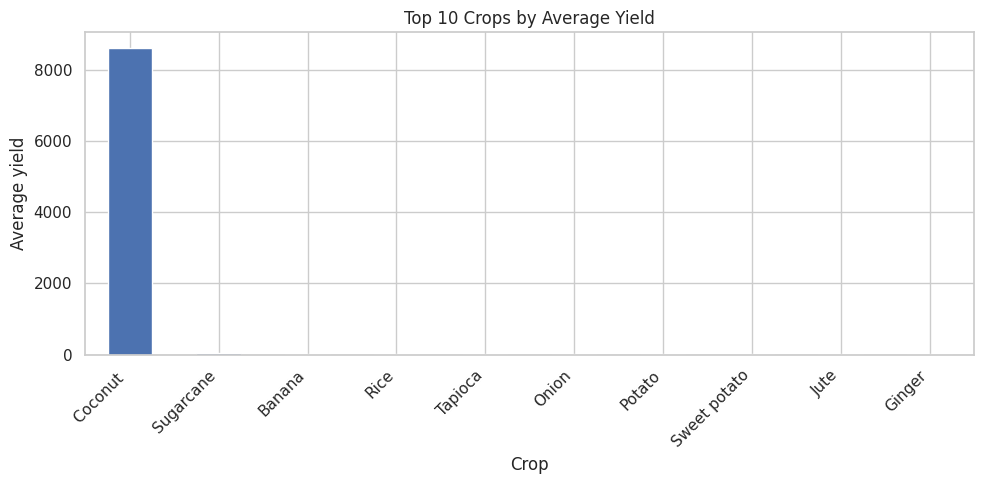

In [ ]:
# 7.1 Bar chart: average yield by crop (top 10 crops)
if crop_col and yield_col:
    plot_data = df_clean.groupby(crop_col)[yield_col].mean().sort_values(ascending=False).head(10)
    plot_data.plot(kind="bar", figsize=(10, 5))
    plt.title("Top 10 Crops by Average Yield")
    plt.xlabel("Crop")
    plt.ylabel("Average yield")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
elif crop_col:
    df_clean[crop_col].value_counts().head(10).plot(kind="bar", figsize=(10, 5))
    plt.title("Top 10 Crop Categories by Number of Records")
    plt.xlabel("Crop")
    plt.ylabel("Record count")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


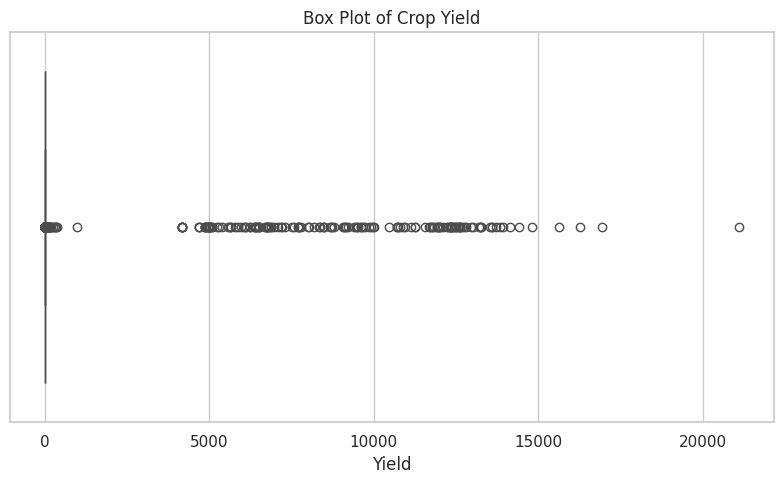

In [ ]:
# 7.3 Box plot: identify spread and possible outliers in crop yield
if yield_col:
    plt.figure(figsize=(8, 5))
    sns.boxplot(x=df_clean[yield_col])
    plt.title("Box Plot of Crop Yield")
    plt.xlabel(yield_col)
    plt.tight_layout()
    plt.show()


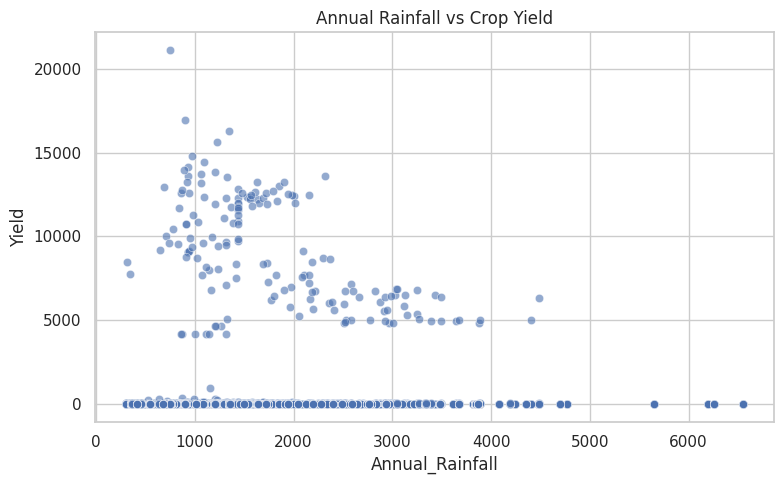

In [ ]:
# 7.4 Scatter plot: rainfall versus crop yield
if rain_col and yield_col:
    plt.figure(figsize=(8, 5))
    sns.scatterplot(data=df_clean, x=rain_col, y=yield_col, alpha=0.6)
    plt.title("Annual Rainfall vs Crop Yield")
    plt.xlabel(rain_col)
    plt.ylabel(yield_col)
    plt.tight_layout()
    plt.show()
elif area_col and production_col:
    plt.figure(figsize=(8, 5))
    sns.scatterplot(data=df_clean, x=area_col, y=production_col, alpha=0.6)
    plt.title("Cultivated Area vs Production")
    plt.tight_layout()
    plt.show()


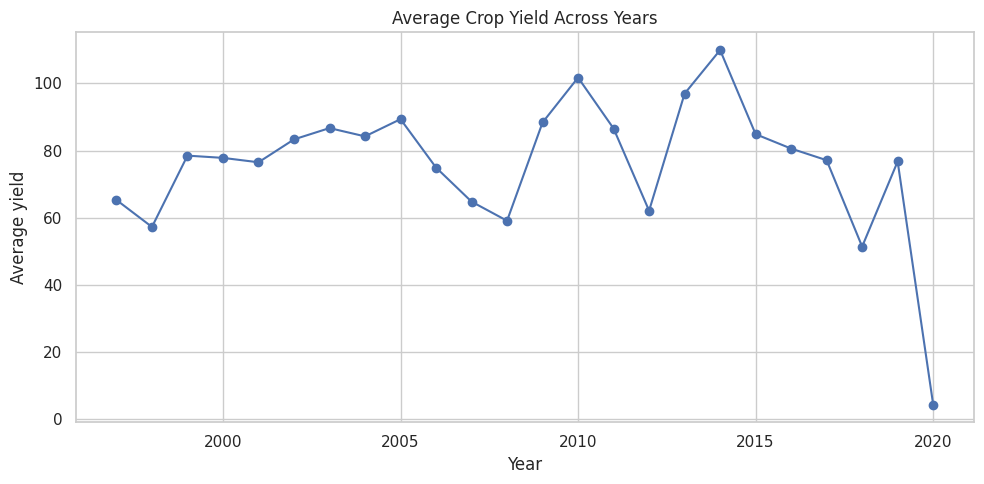

In [ ]:
# 7.5 Line chart: average yield across years (a real time trend if year is available)
if year_col and yield_col:
    yearly_yield = df_clean.groupby(year_col)[yield_col].mean().sort_index()
    plt.figure(figsize=(10, 5))
    plt.plot(yearly_yield.index, yearly_yield.values, marker="o")
    plt.title("Average Crop Yield Across Years")
    plt.xlabel("Year")
    plt.ylabel("Average yield")
    plt.tight_layout()
    plt.show()
else:
    print("A year column or yield column is not available for the time-trend line chart.")


## 8. Encoding Categorical Data

One-hot encoding converts categories into numerical indicator columns. Apply it to a small set of available categorical features to avoid creating an excessively wide table. Keep the encoded data separate from the cleaned dataset.

In [ ]:
encode_cols = [c for c in [crop_col, season_col, state_col] if c is not None]
encode_cols = list(dict.fromkeys(encode_cols))

if encode_cols:
    encoded_data = pd.get_dummies(df_clean[encode_cols], dtype=int, prefix=encode_cols)
    print("Categorical columns encoded:", encode_cols)
    display(encoded_data.head())
    print("Encoded data shape:", encoded_data.shape)
else:
    print("No suitable categorical columns were found for encoding.")


Categorical columns encoded: ['Crop', 'Season', 'State']


,Crop_Arecanut,Crop_Arhar/Tur,Crop_Bajra,Crop_Banana,Crop_Barley,Crop_Black pepper,Crop_Cardamom,Crop_Cashewnut,Crop_Castor seed,Crop_Coconut,Crop_Coriander,Crop_Cotton(lint),Crop_Cowpea(Lobia),Crop_Dry chillies,Crop_Garlic,Crop_Ginger,Crop_Gram,Crop_Groundnut,Crop_Guar seed,Crop_Horse-gram,Crop_Jowar,Crop_Jute,Crop_Khesari,Crop_Linseed,Crop_Maize,Crop_Masoor,Crop_Mesta,Crop_Moong(Green Gram),Crop_Moth,Crop_Niger seed,Crop_Oilseeds total,Crop_Onion,Crop_Other Rabi pulses,Crop_Other Cereals,Crop_Other Kharif pulses,Crop_Other Summer Pulses,Crop_Peas & beans (Pulses),Crop_Potato,Crop_Ragi,Crop_Rapeseed &Mustard,Crop_Rice,Crop_Safflower,Crop_Sannhamp,Crop_Sesamum,Crop_Small millets,Crop_Soyabean,Crop_Sugarcane,Crop_Sunflower,Crop_Sweet potato,Crop_Tapioca,Crop_Tobacco,Crop_Turmeric,Crop_Urad,Crop_Wheat,Crop_other oilseeds,Season_Autumn,Season_Kharif,Season_Rabi,Season_Summer,Season_Whole Year,Season_Winter,State_Andhra Pradesh,State_Arunachal Pradesh,State_Assam,State_Bihar,State_Chhattisgarh,State_Delhi,State_Goa,State_Gujarat,State_Haryana,State_Himachal Pradesh,State_Jammu and Kashmir,State_Jharkhand,State_Karnataka,State_Kerala,State_Madhya Pradesh,State_Maharashtra,State_Manipur,State_Meghalaya,State_Mizoram,State_Nagaland,State_Odisha,State_Puducherry,State_Punjab,State_Sikkim,State_Tamil Nadu,State_Telangana,State_Tripura,State_Uttar Pradesh,State_Uttarakhand,State_West Bengal
0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Encoded data shape: (19689, 91)


## 9. Feature Engineering

In [ ]:
df_features = df_clean.copy()

if year_col:
    df_features["decade"] = (pd.to_numeric(df_features[year_col], errors="coerce") // 10 * 10)

if rain_col:
    valid_rain = df_features[rain_col].dropna()
    if valid_rain.nunique() >= 3:
        df_features["rainfall_category"] = pd.qcut(
            df_features[rain_col], q=3,
            labels=["Low", "Medium", "High"],
            duplicates="drop"
        )

if fert_col and area_col:
    area_values = pd.to_numeric(df_features[area_col], errors="coerce").replace(0, np.nan)
    df_features["fertilizer_per_area"] = pd.to_numeric(
        df_features[fert_col], errors="coerce"
    ) / area_values

if production_col and area_col:
    area_values = pd.to_numeric(df_features[area_col], errors="coerce").replace(0, np.nan)
    df_features["production_per_area_check"] = pd.to_numeric(
        df_features[production_col], errors="coerce"
    ) / area_values

print("Dataset after feature engineering:")
display(df_features.head())
print("Updated shape:", df_features.shape)


Dataset after feature engineering:


,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield,decade,rainfall_category,fertilizer_per_area,production_per_area_check
0,Arecanut,1997.0,Whole Year,Assam,73814.0,56708,2051.4,7024878.38,22882.34,0.796087,1990.0,High,95.17,0.768255
1,Arhar/Tur,1997.0,Kharif,Assam,6637.0,4685,2051.4,631643.29,2057.47,0.710435,1990.0,High,95.17,0.705891
2,Castor seed,1997.0,Kharif,Assam,796.0,22,2051.4,75755.32,246.76,0.238333,1990.0,High,95.17,0.027638
3,Coconut,1997.0,Whole Year,Assam,19656.0,126905000,2051.4,1870661.52,6093.36,5238.051739,1990.0,High,95.17,6456.298331
4,Cotton(lint),1997.0,Kharif,Assam,1739.0,794,2051.4,165500.63,539.09,0.420909,1990.0,High,95.17,0.456584


Updated shape: (19689, 14)


## 10. Feature Scaling

Min-Max scaling transforms selected numerical features to a range between 0 and 1. The scaled values are stored in a separate DataFrame so the original cleaned values remain unchanged. Exclude identifiers and the yield target from the scaling list for this practical demonstration.

In [ ]:
exclude_from_scaling = {yield_col, year_col}
scale_cols = [
    c for c in df_features.select_dtypes(include=np.number).columns
    if c not in exclude_from_scaling and df_features[c].nunique(dropna=True) > 1
]

if scale_cols:
    scaler = MinMaxScaler()
    scaled_values = scaler.fit_transform(df_features[scale_cols])
    df_scaled = pd.DataFrame(
        scaled_values,
        columns=[f"{c}_scaled" for c in scale_cols],
        index=df_features.index
    )
    print("Columns scaled:", scale_cols)
    display(df_scaled.head())
    print("Scaled values range:")
    display(df_scaled.agg(["min", "max"]).T)
else:
    print("No eligible numerical features found for scaling.")


Columns scaled: ['Area', 'Production', 'Annual_Rainfall', 'Fertilizer', 'Pesticide', 'decade', 'fertilizer_per_area', 'production_per_area_check']


,Area_scaled,Production_scaled,Annual_Rainfall_scaled,Fertilizer_scaled,Pesticide_scaled,decade_scaled,fertilizer_per_area_scaled,production_per_area_check_scaled
0,0.001453,8.964274e-06,0.279953,0.001453,0.001453,0.0,0.005054,0.000036
1,0.000131,7.405944e-07,0.279953,0.000131,0.000131,0.0,0.005054,0.000033
2,0.000016,3.477711e-09,0.279953,0.000016,0.000016,0.0,0.005054,0.000001
3,0.000387,2.006086e-02,0.279953,0.000387,0.000387,0.0,0.005054,0.305913
4,0.000034,1.255138e-07,0.279953,0.000034,0.000034,0.0,0.005054,0.000022


Scaled values range:


,min,max
Area_scaled,0.0,1.0
Production_scaled,0.0,1.0
Annual_Rainfall_scaled,0.0,1.0
Fertilizer_scaled,0.0,1.0
Pesticide_scaled,0.0,1.0
decade_scaled,0.0,1.0
fertilizer_per_area_scaled,0.0,1.0
production_per_area_check_scaled,0.0,1.0


## 11. Dataset Validation

In [ ]:
print("Final dataset shape:", df_features.shape)
print("Final column names:")
print(df_features.columns.tolist())

print("Missing values by column:")
display(df_features.isnull().sum().to_frame("Missing Values"))

print("Duplicate rows:", int(df_features.duplicated().sum()))

print("Final dataset preview:")
display(df_features.head())


Final dataset shape: (19689, 14)
Final column names:
['Crop', 'Crop_Year', 'Season', 'State', 'Area', 'Production', 'Annual_Rainfall', 'Fertilizer', 'Pesticide', 'Yield', 'decade', 'rainfall_category', 'fertilizer_per_area', 'production_per_area_check']
Missing values by column:


,Missing Values
Crop,0
Crop_Year,0
Season,0
State,0
Area,0
Production,0
Annual_Rainfall,0
Fertilizer,0
Pesticide,0
Yield,0


Duplicate rows: 0
Final dataset preview:


,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield,decade,rainfall_category,fertilizer_per_area,production_per_area_check
0,Arecanut,1997.0,Whole Year,Assam,73814.0,56708,2051.4,7024878.38,22882.34,0.796087,1990.0,High,95.17,0.768255
1,Arhar/Tur,1997.0,Kharif,Assam,6637.0,4685,2051.4,631643.29,2057.47,0.710435,1990.0,High,95.17,0.705891
2,Castor seed,1997.0,Kharif,Assam,796.0,22,2051.4,75755.32,246.76,0.238333,1990.0,High,95.17,0.027638
3,Coconut,1997.0,Whole Year,Assam,19656.0,126905000,2051.4,1870661.52,6093.36,5238.051739,1990.0,High,95.17,6456.298331
4,Cotton(lint),1997.0,Kharif,Assam,1739.0,794,2051.4,165500.63,539.09,0.420909,1990.0,High,95.17,0.456584


## 12. Save the Final Dataset

Save the cleaned and feature-engineered dataset as a CSV file. Google Colab will prompt you to download it.

In [ ]:
output_file = "crop_yield_features_cleaned.csv"
df_features.to_csv(output_file, index=False)
print("Saved:", output_file)

try:
    from google.colab import files
    files.download(output_file)
except ImportError:
    print("CSV saved in the current working directory.")


Saved: crop_yield_features_cleaned.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. Conclusion

This practical demonstrated how raw agricultural data can be prepared for analysis using data inspection, missing-value imputation, visualization, categorical encoding, feature engineering, and feature scaling. Derived variables such as decade, rainfall category, fertilizer per area, and production per area can make the dataset more useful for exploratory analysis. Any final interpretation should be based on the actual data and plots generated by running the notebook.